In [1]:
import random
import statistics
import time
import matplotlib.pyplot as plt

POPULATION_SIZE = 10
ITERATIONS = 50
NUM_RUNS = 50
LOWER_BOUND = -5
UPPER_BOUND = 10
random.seed(42)

def f1(x):
    return 10 - (x - 3)**2

def run_baseline():
    population = [
        random.uniform(LOWER_BOUND, UPPER_BOUND)
        for _ in range(POPULATION_SIZE)
    ]
    populations = [population]
    best_ever = max(population, key=f1)
    history = [f1(best_ever)]
    for _ in range(ITERATIONS):
        new_population = []
        for _ in range(POPULATION_SIZE):
            xa, xb, xc = random.sample(population, 3)
            c = (xa + xb + xc) / 3
            xp = max(
                [xa, xb, xc],
                key=f1
            )
            r = random.uniform(0, 1.2)
            xnew = c + r * (xp - c)
            xnew = max(LOWER_BOUND, min(UPPER_BOUND, xnew))
            new_population.append(xnew)
        population = new_population
        populations.append(population)
        current_best = max(population, key=f1)
        if f1(current_best) > f1(best_ever):
            best_ever = current_best
        history.append(f1(best_ever))

    return {
        "best_x": best_ever,
        "best_f": f1(best_ever),
        "history": history,
        "populations": populations
    }

start_time = time.perf_counter()
results = [
    run_baseline()
    for _ in range(NUM_RUNS)
]
execution_time = time.perf_counter() - start_time

In [2]:
print("BEST SOLUTION OF EACH RUN")
print(f"{'Run':>5} {'Best x':>12} {'Best f(x)':>12}")
print("-" * 31)

for run, result in enumerate(results, start=1):
    print(
        f"{run:>5} "
        f"{result['best_x']:>12.4f} "
        f"{result['best_f']:>12.6f}"
    )

best_values = [result["best_f"] for result in results]

BEST SOLUTION OF EACH RUN
  Run       Best x    Best f(x)
-------------------------------
    1       2.9998    10.000000
    2       2.9995    10.000000
    3       1.8833     8.752944
    4       3.0068     9.999954
    5       2.9996    10.000000
    6       3.0000    10.000000
    7       3.0433     9.998126
    8       2.9864     9.999815
    9       3.0001    10.000000
   10       3.2567     9.934082
   11       3.0005    10.000000
   12       3.0022     9.999995
   13       2.9250     9.994382
   14       2.9652     9.998791
   15       2.9874     9.999840
   16       3.0027     9.999993
   17       2.9398     9.996374
   18       3.0001    10.000000
   19       3.0002    10.000000
   20       2.9849     9.999773
   21       3.0009     9.999999
   22       2.9965     9.999988
   23       3.0000    10.000000
   24       3.0886     9.992156
   25       3.0000    10.000000
   26       3.0007    10.000000
   27       2.9997    10.000000
   28       3.0019     9.999997
   29       3.

In [3]:
print("EVALUATION METRICS")
print(f"Best overall  : {max(best_values):.6f}")
print(f"Average best  : {statistics.mean(best_values):.6f}")
print(f"Worst overall : {min(best_values):.6f}")
print(f"Std of best   : {statistics.stdev(best_values):.6f}")
print(f"Time ({NUM_RUNS} runs) : {execution_time:.4f} s")

EVALUATION METRICS
Best overall  : 10.000000
Average best  : 9.968710
Worst overall : 8.752944
Std of best   : 0.176572
Time (50 runs) : 0.0494 s


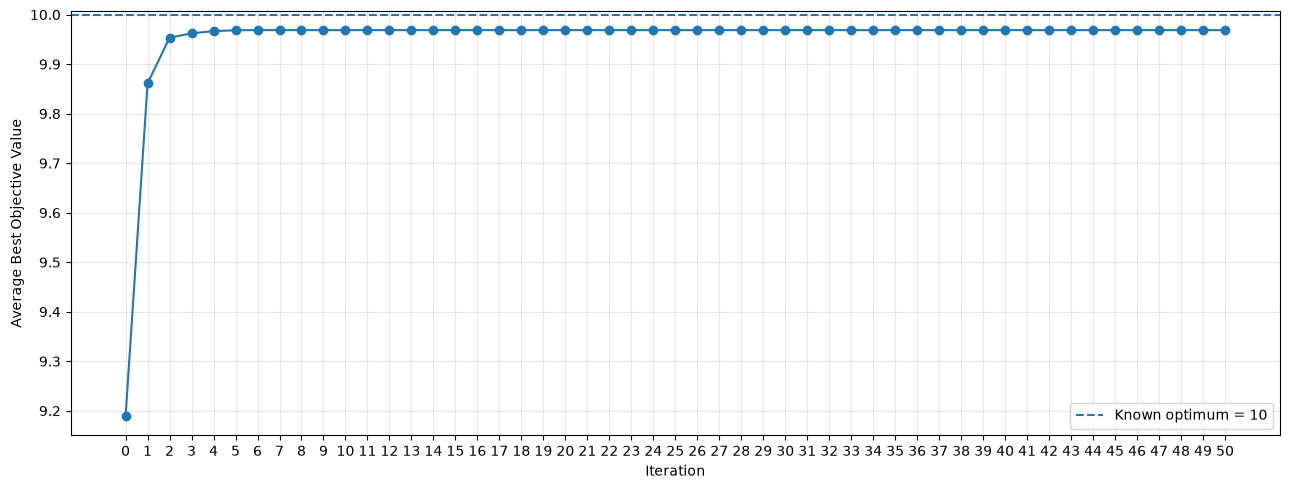

In [4]:
mean_history = [
    statistics.mean(result["history"][i] for result in results)
    for i in range(ITERATIONS + 1)
]

plt.figure(figsize=(13, 5))

plt.plot(
    range(ITERATIONS + 1),
    mean_history,
    marker="o"
)

plt.axhline(
    y=10,
    linestyle="--",
    label="Known optimum = 10"
)

plt.xlabel("Iteration")
plt.ylabel("Average Best Objective Value")
plt.xticks(range(ITERATIONS + 1))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()